<a href="https://colab.research.google.com/github/sdow-docs/Data_Analytics/blob/data_cleaning/Sarah_Colab_Works.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [126]:
### Start first by loading my libraries.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [128]:
### Load my dataset.
df = pd.read_csv('social_media_vs_productivity.csv')

In [129]:
### Inital look at the dataset.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             30000 non-null  int64  
 1   gender                          30000 non-null  object 
 2   job_type                        30000 non-null  object 
 3   daily_social_media_time         27235 non-null  float64
 4   social_platform_preference      30000 non-null  object 
 5   number_of_notifications         30000 non-null  int64  
 6   work_hours_per_day              30000 non-null  float64
 7   perceived_productivity_score    28386 non-null  float64
 8   actual_productivity_score       27635 non-null  float64
 9   stress_level                    28096 non-null  float64
 10  sleep_hours                     27402 non-null  float64
 11  screen_time_before_sleep        27789 non-null  float64
 12  breaks_during_work              

As this is a large datasset, I am going to remove all rows that are missing at least one value in a column. I am also going to look for and remove duplicate rows (if any).

In [130]:
df = df.dropna()

In [131]:
df.duplicated().sum()

np.int64(0)

No duplicates were found. After removing rows containing at least one missing value, this is still a very large dataset. I want to only use a sample size of 15% for analysis and I want to make sure it is the same sample each time.

In [132]:
df = df.sample(frac=0.015, random_state=42)

In [133]:
## How big is the dataset now?
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 256 entries, 3661 to 1911
Data columns (total 19 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             256 non-null    int64  
 1   gender                          256 non-null    object 
 2   job_type                        256 non-null    object 
 3   daily_social_media_time         256 non-null    float64
 4   social_platform_preference      256 non-null    object 
 5   number_of_notifications         256 non-null    int64  
 6   work_hours_per_day              256 non-null    float64
 7   perceived_productivity_score    256 non-null    float64
 8   actual_productivity_score       256 non-null    float64
 9   stress_level                    256 non-null    float64
 10  sleep_hours                     256 non-null    float64
 11  screen_time_before_sleep        256 non-null    float64
 12  breaks_during_work              256 n

The sample size is now 256 rows and is a lot better to manage.

In [134]:
### Run descriptive statistics to better understand the dataset.
### For example, the minimum and maximum age will help me with createding age groups.
df.describe()

,age,daily_social_media_time,number_of_notifications,work_hours_per_day,perceived_productivity_score,actual_productivity_score,stress_level,sleep_hours,screen_time_before_sleep,breaks_during_work,coffee_consumption_per_day,days_feeling_burnout_per_month,weekly_offline_hours,job_satisfaction_score
count,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000,256.000000
mean,41.492188,3.224294,60.675781,6.945769,5.245517,4.714078,5.230469,6.472758,1.045010,4.906250,2.070312,16.941406,10.339373,4.767923
std,14.319599,2.280408,7.282019,1.916250,2.000719,1.871839,2.893808,1.444266,0.659757,3.199111,1.509102,9.212124,7.016541,2.088768
min,18.000000,0.000000,40.000000,0.000000,2.085304,0.792545,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.045191
25%,29.000000,1.760897,56.000000,5.736318,3.411664,3.094552,3.000000,5.471441,0.559335,2.000000,1.000000,10.000000,4.489022,3.198783
50%,41.500000,3.099739,61.000000,6.957974,5.003158,4.653814,5.000000,6.422515,0.966213,5.000000,2.000000,18.000000,9.890189,4.822787
75%,53.000000,4.326895,65.000000,8.226792,6.805548,6.287985,8.000000,7.509902,1.475584,8.000000,3.000000,25.000000,15.707038,6.360286
max,65.000000,17.724981,87.000000,12.000000,8.998854,8.738220,10.000000,9.904089,3.000000,10.000000,6.000000,31.000000,28.713578,10.000000


In [127]:
### Next I want to define my chart colors to represent gender.
gender_colors = {
    'Male': '#3498DB',    # Blue
    'Female': '#E67EBD',  # Pink
    'Other': '#50C878'    # Green
}


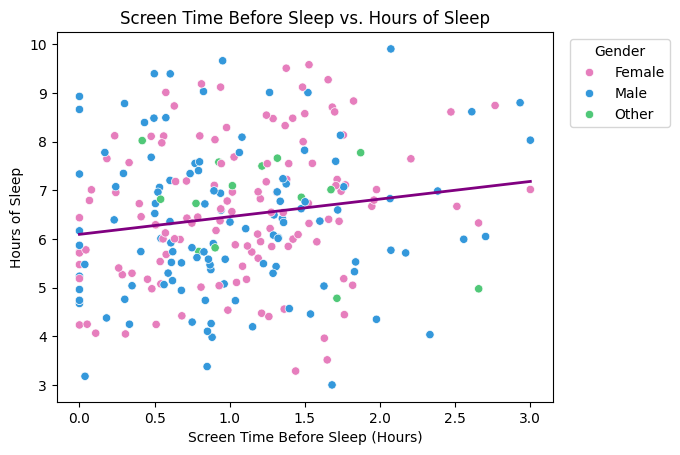

In [162]:
sns.scatterplot(
      data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',hue='gender',palette=gender_colors)

sns.regplot(
    data=df,
    x='screen_time_before_sleep',
    y='sleep_hours',
    scatter=False,
    color='purple',ci=None,
    line_kws={'linewidth': 2}
)


plt.title('Screen Time Before Sleep vs. Hours of Sleep')
plt.xlabel('Screen Time Before Sleep (Hours)')
plt.ylabel('Hours of Sleep')
plt.legend(title='Gender', loc='upper left', bbox_to_anchor=(1.02, 1))

plt.show()

In [135]:
## Create age groups
bins = [18, 25, 30, 35, 40, 45, 50, 55, 60, 65]
labels = ['18-24', '25-29', '30-34', '35-39',
          '40-44', '45-49', '50-54', '55-59', '60-65']

df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, include_lowest=True,
    right=True,)
df[['age', 'age_group']].head(20)

,age,age_group
3661,36,35-39
13279,21,18-24
29735,23,18-24
14700,36,35-39
7091,41,40-44
7137,38,35-39
1738,47,45-49
21709,18,18-24
8927,58,55-59
19381,33,30-34


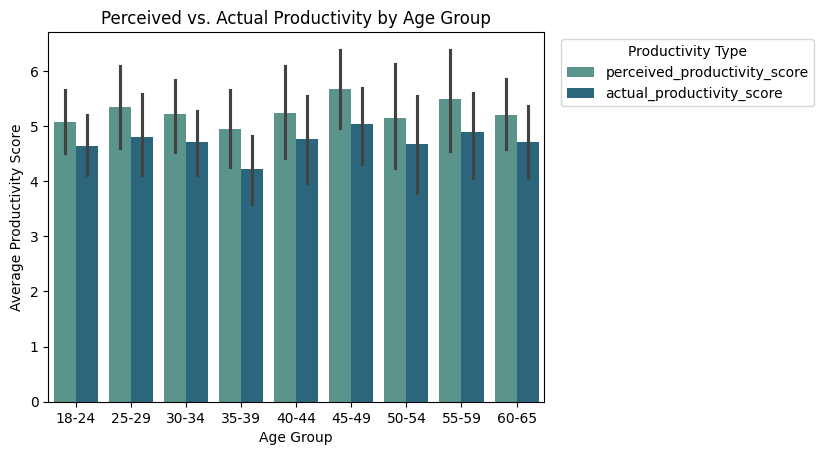

In [163]:
sns.color_palette("crest", as_cmap=True)
productivity_df = df.melt(
    id_vars='age_group',
    value_vars=[
        'perceived_productivity_score',
        'actual_productivity_score'
    ],
    var_name='productivity_type',
    value_name='productivity_score'
)
sns.barplot(
    data=productivity_df,
    x='age_group',
    y='productivity_score',
    hue='productivity_type',
    palette='crest'
)

plt.title('Perceived vs. Actual Productivity by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Productivity Score')
plt.legend(title='Productivity Type', loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()

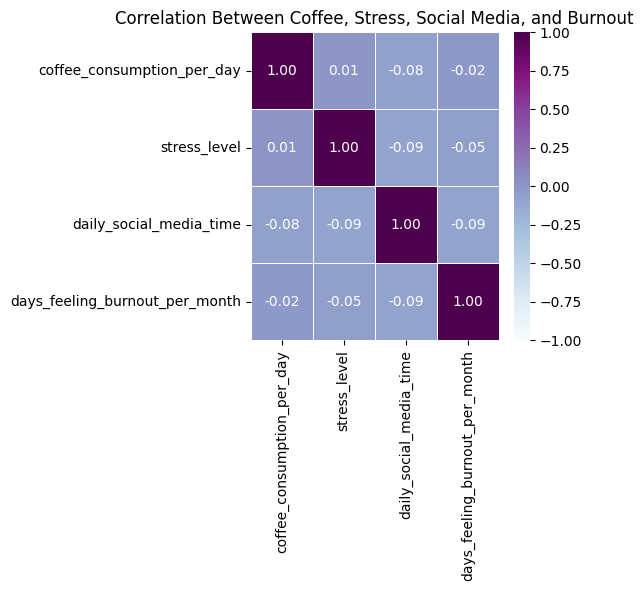

In [154]:
### Create a heatmap to determine correlations.

correlation = df[
    ['coffee_consumption_per_day','stress_level', 'daily_social_media_time', 'days_feeling_burnout_per_month']
].corr()

plt.figure(figsize=(4, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='BuPu',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Correlation Between Coffee, Stress, Social Media, and Burnout')
plt.show()